# AMR Guardian — data pipeline & antibiogram analysis

This notebook documents where the dashboard's data comes from and checks how far it can be trusted.

| Step | What it does | Output |
|---|---|---|
| 1 | Load WHO GLASS **Pakistan 2023** resistance rates (parse the raw WHO exports if present, otherwise use the committed table) | `data/glass_rates_pakistan_2023.csv` |
| 2 | Generate the **synthetic** 300-isolate demo dataset used by the app | `amr_data.csv` (verified to be identical) |
| 3 | Antibiogram tables + heatmap, with low-sample (n < 30) cells masked | `outputs/notebook/` |
| 4 | Validity check: demo-data rates vs. the WHO source rates | table + plot |
| A | Appendix: structured parser for LLM AMR responses (not used by the app) | — |

**Run it:** locally from the repo root (`pip install -r requirements-dev.txt`, then open this notebook), or in Google Colab —
the first cell clones the repo automatically when it is not found.

> **Note:** The demo dataset is synthetic: organism–antibiotic results follow national WHO rates, but **cities and dates are random**.

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
import os, sys, subprocess
from pathlib import Path

try:
    import amr_utils
except ModuleNotFoundError:
    # Running outside the repo (e.g. Google Colab): fetch it once and work from there.
    if not Path("amr-guardian").exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/manan348/amr-guardian.git"], check=True)
    os.chdir("amr-guardian")
    sys.path.insert(0, os.getcwd())
    import amr_utils

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT          = Path.cwd()
DATA_DIR      = ROOT / "data"
GLASS_RAW_DIR = DATA_DIR / "glass_raw"      # put the WHO GLASS CSV exports here to re-parse them
GLASS_CSV     = DATA_DIR / "glass_rates_pakistan_2023.csv"
DEMO_CSV      = ROOT / "amr_data.csv"
OUT_DIR       = ROOT / "outputs" / "notebook"   # DVC pipeline outputs live in outputs/
OUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_ISOLATES = 30      # CLSI M39: don't report a rate from fewer isolates
WRITE_DATA   = False   # set True to overwrite amr_data.csv with the regenerated data

pd.set_option("display.width", 140)
print("Project root:", ROOT)

Project root: D:\New Project\amr-guardian-main


## Step 1 — WHO GLASS Pakistan 2023 resistance rates

The raw files are the *"Resistance to individual antibiotics (2023)\_Pakistan"* CSV exports from the
[WHO GLASS dashboard](https://worldhealthorg.shinyapps.io/glass-dashboard/), one per pathogen.
Each file has a metadata header (with `Pathogen: …`) followed by a `Plot data` table.

If `data/glass_raw/` contains those exports they are parsed again; otherwise the committed table
(extracted from them in 2025) is used. Duplicate exports of the same pathogen are removed.

In [2]:
import re
from io import StringIO

# WHO antibiotic group → representative drug name used in the app
ANTIBIOTIC_MAP = {
    "Carbapenem resistance":                      "Meropenem",
    "Third-generation cephalosporin resistance":  "Ceftriaxone",
    "Fourth-generation cephalosporin resistance": "Cefepime",
    "Fluoroquinolone resistance":                 "Ciprofloxacin",
    "Sulfonamides and trimethoprim resistance":   "Co-trimoxazole",
    "Polymyxin resistance":                       "Colistin",
    "Penicillin resistance":                      "Ampicillin",
    "Aminoglycoside resistance":                  "Gentamicin",
    "Glycopeptide resistance":                    "Vancomycin",
    "Macrolide resistance":                       "Azithromycin",
    "Oxazolidinone resistance":                   "Linezolid",
}

def parse_glass_file(path):
    lines = path.read_text(encoding="utf-8-sig").splitlines(keepends=True)
    pathogen = next((m.group(1).strip() for l in lines
                     if (m := re.search(r"Pathogen:\s*(.+)", l))), None)
    start = next((i + 1 for i, l in enumerate(lines) if l.strip() == "Plot data"), None)
    if pathogen is None or start is None:
        print(f"  WARNING: could not parse {path.name}")
        return None
    df = pd.read_csv(StringIO("".join(lines[start:])))
    df.columns = df.columns.str.strip().str.replace('"', "")
    if "AgeGrouping" in df.columns:                      # avoid double counting age strata
        df = df[df["AgeGrouping"] == "Total"]
    df["antibiotic"] = df["AntibioticGroup"].map(ANTIBIOTIC_MAP).fillna(df["AntibioticGroup"])
    df["organism"] = pathogen
    return (df.groupby(["organism", "antibiotic"], as_index=False, sort=False)
              .agg(percent_resistant=("PercentResistant", "mean"),
                   n_resistant=("Resistant", "sum"),
                   n_tested=("InterpretableAST", "sum")))

raw_files = sorted(GLASS_RAW_DIR.glob("*.csv")) if GLASS_RAW_DIR.exists() else []
if raw_files:
    print(f"Parsing {len(raw_files)} WHO GLASS exports from {GLASS_RAW_DIR}")
    parts = [p for f in raw_files if (p := parse_glass_file(f)) is not None]
    glass = (pd.concat(parts, ignore_index=True)
               .drop_duplicates(["organism", "antibiotic"])   # same pathogen exported twice
               .round({"percent_resistant": 6}))
    glass.to_csv(GLASS_CSV, index=False)
    print("Saved", GLASS_CSV)
else:
    glass = pd.read_csv(GLASS_CSV)
    print(f"No raw exports in {GLASS_RAW_DIR} — using committed table {GLASS_CSV.name}")

assert not glass.duplicated(["organism", "antibiotic"]).any()
glass

No raw exports in D:\New Project\amr-guardian-main\data\glass_raw — using committed table glass_rates_pakistan_2023.csv


,organism,antibiotic,percent_resistant,n_resistant,n_tested
0,Acinetobacter spp.,Colistin,2.523659,24,951
1,Acinetobacter spp.,Gentamicin,55.832330,2635,4705
2,Acinetobacter spp.,Meropenem,67.754641,3346,4938
3,Acinetobacter spp.,Minocycline,3.416856,30,878
4,Klebsiella pneumoniae,Cefepime,77.083333,370,480
5,Klebsiella pneumoniae,Ceftriaxone,84.190384,3365,3936
6,Klebsiella pneumoniae,Ciprofloxacin,65.782866,2853,4124
7,Klebsiella pneumoniae,Co-trimoxazole,75.476190,1268,1680
8,Klebsiella pneumoniae,Colistin,21.739130,100,460
9,Klebsiella pneumoniae,Meropenem,59.455073,3100,5433


## Step 2 — Generate the synthetic demo dataset

`amr_utils.generate_demo_data` draws 300 isolates. For each row it picks a random organism–antibiotic
pair from the WHO table and samples the result from that pair's national resistance rate
(Intermediate is a fixed 10% band). **City and date are uniformly random**, so city/date
patterns in the dashboard carry no information.

The cell checks that the regenerated data is identical to the committed `amr_data.csv`.

In [3]:
demo = amr_utils.generate_demo_data(glass, n_rows=300, seed=42)

committed = pd.read_csv(DEMO_CSV)
print("Identical to committed amr_data.csv:", demo.equals(committed))
if WRITE_DATA:
    demo.to_csv(DEMO_CSV, index=False)
    print("Wrote", DEMO_CSV)

print("\nResult distribution:")
print(demo["result"].value_counts().to_string())
print("\nIsolates per city (random by construction):")
print(demo["city"].value_counts().to_string())

Identical to committed amr_data.csv: True

Result distribution:
result
Resistant       140
Susceptible     125
Intermediate     35

Isolates per city (random by construction):
city
Quetta        48
Peshawar      44
Lahore        43
Karachi       35
Islamabad     35
Multan        34
Faisalabad    32
Rawalpindi    29


## Step 3 — Antibiogram

Rows = organisms, columns = antibiotics, values = % resistant. Following CLSI M39, cells with fewer than
30 isolates are shown but flagged — with only 300 isolates spread over 23 pairs, **every** cell of the demo
data is below that threshold, which is exactly why the app now warns about low sample sizes.

In [4]:
rates = amr_utils.rate_table(demo, ["organism", "antibiotic"])
antibiogram = rates["rate"].unstack()
counts      = rates["n"].unstack().reindex_like(antibiogram)

print("% resistant (n in brackets, * = n < 30)")
labelled = antibiogram.copy().astype(object)
for o in antibiogram.index:
    for a in antibiogram.columns:
        v, n = antibiogram.loc[o, a], counts.loc[o, a]
        labelled.loc[o, a] = "" if pd.isna(v) else f"{v:.0f}% ({int(n)}){'*' if n < MIN_ISOLATES else ''}"
display(labelled)

city_antibiogram = amr_utils.rate_table(demo, ["city", "organism", "antibiotic"])
susceptibility_index = (demo.assign(s=demo["result"].eq("Susceptible"))
                            .groupby("organism")["s"].mean().mul(100).round(1)
                            .sort_values().rename("% susceptible"))

antibiogram.to_csv(OUT_DIR / "antibiogram_global.csv")
city_antibiogram.to_csv(OUT_DIR / "antibiogram_by_city.csv")
print("\nSusceptibility index (lower = harder to treat):")
print(susceptibility_index.to_string())
print("\nSaved antibiogram CSVs to", OUT_DIR)

% resistant (n in brackets, * = n < 30)


antibiotic,Ampicillin,Cefepime,Ceftriaxone,Ciprofloxacin,Co-trimoxazole,Colistin,Gentamicin,Imipenem,Meropenem,Minocycline
organism,,,,,,,,,,
Acinetobacter spp.,,,,,,0% (10)*,54% (13)*,,71% (14)*,7% (15)*
Escherichia coli,,89% (18)*,78% (18)*,50% (8)*,60% (10)*,0% (10)*,,,9% (11)*,
Klebsiella pneumoniae,,90% (10)*,80% (10)*,53% (17)*,83% (18)*,50% (12)*,,,46% (11)*,
Salmonella spp.,,,40% (20)*,29% (17)*,,,,0% (15)*,0% (11)*,
Streptococcus pneumoniae,46% (13)*,,0% (7)*,,83% (12)*,,,,,



Susceptibility index (lower = harder to treat):
organism
Klebsiella pneumoniae       25.6
Escherichia coli            37.3
Streptococcus pneumoniae    40.6
Acinetobacter spp.          48.1
Salmonella spp.             61.9

Saved antibiogram CSVs to D:\New Project\amr-guardian-main\outputs


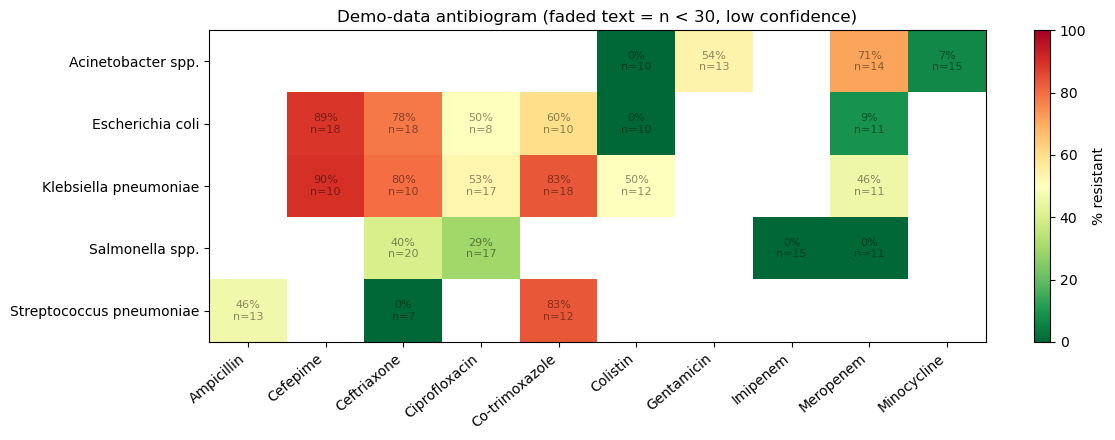

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(antibiogram.values, cmap="RdYlGn_r", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(antibiogram.columns)), antibiogram.columns, rotation=40, ha="right")
ax.set_yticks(range(len(antibiogram.index)), antibiogram.index)
for i in range(antibiogram.shape[0]):
    for j in range(antibiogram.shape[1]):
        v, n = antibiogram.iat[i, j], counts.iat[i, j]
        if not pd.isna(v):
            ax.text(j, i, f"{v:.0f}%\nn={int(n)}", ha="center", va="center", fontsize=8,
                    color="black", alpha=0.45 if n < MIN_ISOLATES else 1.0)
fig.colorbar(im, ax=ax, label="% resistant")
ax.set_title("Demo-data antibiogram (faded text = n < 30, low confidence)")
fig.tight_layout()
fig.savefig(OUT_DIR / "antibiogram_heatmap.png", dpi=150)
plt.show()

## Step 4 — Validity check: demo data vs. WHO source

How close are the rates the dashboard shows to the WHO rates they were sampled from?
The 95% Wilson interval shows how much a rate based on ~13 isolates can move by chance alone.

In [6]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (centre - half), 100 * (centre + half)

cmp = (demo.groupby(["organism", "antibiotic"])["result"]
           .agg(n="size", k=lambda s: (s == "Resistant").sum())
           .reset_index()
           .merge(glass[["organism", "antibiotic", "percent_resistant"]], on=["organism", "antibiotic"]))
cmp["demo_rate"] = (100 * cmp["k"] / cmp["n"]).round(1)
cmp["who_rate"]  = cmp["percent_resistant"].round(1)
cmp[["ci_low", "ci_high"]] = [tuple(round(x, 1) for x in wilson(k, n)) for k, n in zip(cmp["k"], cmp["n"])]
cmp["who_inside_ci"] = cmp["who_rate"].between(cmp["ci_low"], cmp["ci_high"])
cmp["abs_diff"] = (cmp["demo_rate"] - cmp["who_rate"]).abs()
cmp = cmp.drop(columns=["percent_resistant", "k"]).sort_values("abs_diff", ascending=False)

print(f"Median absolute difference: {cmp['abs_diff'].median():.1f} percentage points")
print(f"Largest difference:         {cmp['abs_diff'].max():.1f} pp "
      f"({cmp.iloc[0]['organism']} / {cmp.iloc[0]['antibiotic']}, n={cmp.iloc[0]['n']})")
print(f"WHO rate inside the 95% CI: {cmp['who_inside_ci'].sum()} of {len(cmp)} pairs")
cmp

Median absolute difference: 5.3 percentage points
Largest difference:         28.3 pp (Klebsiella pneumoniae / Colistin, n=12)
WHO rate inside the 95% CI: 22 of 23 pairs


,organism,antibiotic,n,demo_rate,who_rate,ci_low,ci_high,who_inside_ci,abs_diff
14,Klebsiella pneumoniae,Colistin,12,50.0,21.7,25.4,74.6,False,28.3
6,Escherichia coli,Ciprofloxacin,8,50.0,76.0,21.5,78.5,True,26.0
9,Escherichia coli,Meropenem,11,9.1,24.1,1.6,37.7,True,15.0
20,Streptococcus pneumoniae,Ampicillin,13,46.2,31.4,23.2,70.9,True,14.8
15,Klebsiella pneumoniae,Meropenem,11,45.5,59.5,21.3,72.0,True,14.0
10,Klebsiella pneumoniae,Cefepime,10,90.0,77.1,59.6,98.2,True,12.9
12,Klebsiella pneumoniae,Ciprofloxacin,17,52.9,65.8,31.0,73.8,True,12.9
7,Escherichia coli,Co-trimoxazole,10,60.0,71.4,31.3,83.2,True,11.4
4,Escherichia coli,Cefepime,18,88.9,79.5,67.2,96.9,True,9.4
16,Salmonella spp.,Ceftriaxone,20,40.0,49.2,21.9,61.3,True,9.2


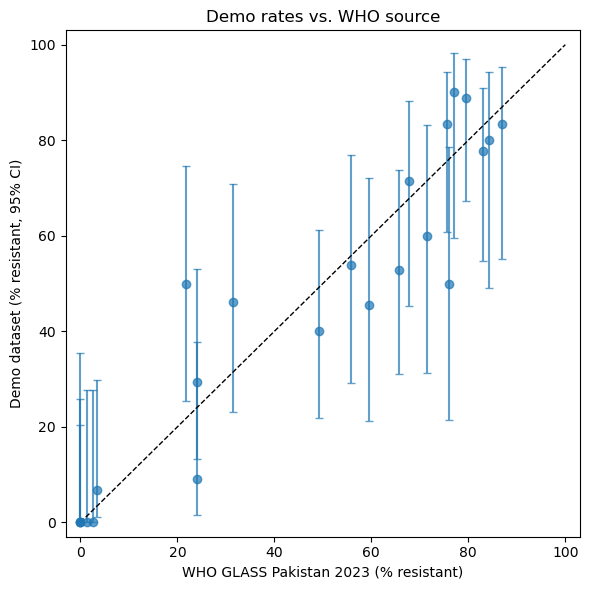

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.errorbar(cmp["who_rate"], cmp["demo_rate"],
            yerr=[cmp["demo_rate"] - cmp["ci_low"], cmp["ci_high"] - cmp["demo_rate"]],
            fmt="o", alpha=0.7, capsize=3)
ax.plot([0, 100], [0, 100], "k--", lw=1)
ax.set(xlabel="WHO GLASS Pakistan 2023 (% resistant)", ylabel="Demo dataset (% resistant, 95% CI)",
       xlim=(-3, 103), ylim=(-3, 103), title="Demo rates vs. WHO source")
fig.tight_layout()
plt.show()

**Take-away:** organism–antibiotic rates in the demo data are noisy but consistent with the WHO source
(differences are within sampling error for most pairs). Anything finer — per city, per month — is noise.
For real surveillance, upload real isolate-level lab data in the app.

## Appendix — structured parser for LLM AMR responses

An earlier, richer response parser (`GroqAMRParser`) that turns an LLM's JSON answer into typed
`ResistanceProfile` objects with risk levels and recommendations. **The dashboard does not use it** — it uses
the simpler `amr_utils.parse_llm_records`. It is kept here for reference and future work.

In [8]:
from __future__ import annotations

import json
import re
import logging
from typing import Any
from dataclasses import dataclass, field

logger = logging.getLogger(__name__)


# ─────────────────────────────────────────────
# Data Models
# ─────────────────────────────────────────────

@dataclass
class ResistanceProfile:
    pathogen: str
    antibiotic: str
    resistance_level: str          # RESISTANT / INTERMEDIATE / SUSCEPTIBLE
    mic_value: str | None = None   # Minimum Inhibitory Concentration
    confidence_score: float = 0.0  # 0.0 – 1.0
    evidence_basis: str = ""
    alternative_antibiotics: list[str] = field(default_factory=list)
    notes: str = ""


@dataclass
class AMRParseResult:
    raw_response: str
    resistance_profiles: list[ResistanceProfile] = field(default_factory=list)
    risk_level: str = "UNKNOWN"         # LOW / MEDIUM / HIGH / CRITICAL
    recommended_actions: list[str] = field(default_factory=list)
    treatment_guidelines: list[str] = field(default_factory=list)
    warnings: list[str] = field(default_factory=list)
    parse_errors: list[str] = field(default_factory=list)
    metadata: dict[str, Any] = field(default_factory=dict)


# ─────────────────────────────────────────────
# Constants
# ─────────────────────────────────────────────

RESISTANCE_LEVELS = {"RESISTANT", "INTERMEDIATE", "SUSCEPTIBLE", "R", "I", "S"}

RESISTANCE_LEVEL_MAP = {
    "R": "RESISTANT",
    "I": "INTERMEDIATE",
    "S": "SUSCEPTIBLE",
    "RESISTANT": "RESISTANT",
    "INTERMEDIATE": "INTERMEDIATE",
    "SUSCEPTIBLE": "SUSCEPTIBLE",
}

RISK_LEVELS = {"LOW", "MEDIUM", "HIGH", "CRITICAL"}

VALID_RISK_KEYWORDS = {
    "critical": "CRITICAL",
    "high": "HIGH",
    "medium": "MEDIUM",
    "moderate": "MEDIUM",
    "low": "LOW",
}

COMMON_PATHOGENS = {
    "e. coli", "escherichia coli", "staphylococcus aureus", "mrsa",
    "klebsiella pneumoniae", "acinetobacter baumannii", "pseudomonas aeruginosa",
    "enterococcus faecium", "streptococcus pneumoniae", "salmonella",
}

COMMON_ANTIBIOTICS = {
    "amoxicillin", "ampicillin", "azithromycin", "cefazolin", "ceftriaxone",
    "ciprofloxacin", "clindamycin", "doxycycline", "erythromycin", "gentamicin",
    "levofloxacin", "linezolid", "meropenem", "metronidazole", "oxacillin",
    "penicillin", "piperacillin", "rifampin", "tetracycline", "trimethoprim",
    "vancomycin",
}


# ─────────────────────────────────────────────
# Core Parser
# ─────────────────────────────────────────────

class GroqAMRParser:
    """
    Parses Groq LLM responses for AMR Guardian.
    Handles JSON-structured responses, semi-structured text,
    and falls back to regex extraction when needed.
    """

    def __init__(self, strict_mode: bool = False):
        """
        Args:
            strict_mode: If True, raises ValueError on unrecognised pathogens
                         or antibiotics. If False, logs a warning and continues.
        """
        self.strict_mode = strict_mode

    # ── Public entry point ──────────────────────────────────────────────────

    def parse(self, groq_response: str | dict) -> AMRParseResult:
        """
        Main parser entry point.

        Accepts:
          - A raw string (Groq API message content)
          - A dict (already-decoded Groq API response object)

        Returns:
          AMRParseResult with all extracted data.
        """
        raw_text = self._extract_text(groq_response)
        result = AMRParseResult(raw_response=raw_text)

        try:
            json_data = self._try_extract_json(raw_text)
            if json_data:
                self._parse_json_response(json_data, result)
            else:
                self._parse_text_response(raw_text, result)
        except Exception as exc:
            logger.exception("Unexpected error during AMR parsing")
            result.parse_errors.append(f"Fatal parse error: {exc}")

        self._validate_result(result)
        return result

    # ── Text extraction ──────────────────────────────────────────────────────

    def _extract_text(self, response: str | dict) -> str:
        if isinstance(response, str):
            return response.strip()
        if isinstance(response, dict):
            # Standard Groq / OpenAI-compatible response shape
            try:
                return response["choices"][0]["message"]["content"].strip()
            except (KeyError, IndexError, TypeError):
                pass
            # Flat dict with a 'content' key
            if "content" in response:
                return str(response["content"]).strip()
        raise ValueError(f"Unsupported response type: {type(response)}")

    # ── JSON extraction ──────────────────────────────────────────────────────

    def _try_extract_json(self, text: str) -> dict | list | None:
        """
        Try to extract a JSON block from the text.
        Handles ```json ... ``` fences and bare JSON objects/arrays.
        """
        # Fenced code block
        fence_match = re.search(
            r"```(?:json)?\s*(\{[\s\S]*?\}|\[[\s\S]*?\])\s*```",
            text,
            re.IGNORECASE,
        )
        if fence_match:
            try:
                return json.loads(fence_match.group(1))
            except json.JSONDecodeError:
                pass

        # Bare JSON object
        obj_match = re.search(r"\{[\s\S]*\}", text)
        if obj_match:
            try:
                return json.loads(obj_match.group())
            except json.JSONDecodeError:
                pass

        return None

    # ── JSON-path parsing ────────────────────────────────────────────────────

    def _parse_json_response(self, data: dict | list, result: AMRParseResult) -> None:
        if isinstance(data, list):
            for item in data:
                self._parse_single_profile(item, result)
            return

        # Top-level resistance profiles
        profiles_raw = (
            data.get("resistance_profiles")
            or data.get("resistanceProfiles")
            or data.get("profiles")
            or (data.get("pathogen") and [data])   # single-profile response
            or []
        )
        for profile_data in profiles_raw:
            self._parse_single_profile(profile_data, result)

        # Risk level
        risk_raw = (
            data.get("risk_level")
            or data.get("riskLevel")
            or data.get("overall_risk")
            or ""
        )
        result.risk_level = self._normalise_risk(risk_raw)

        # Lists
        result.recommended_actions = self._coerce_list(
            data.get("recommended_actions") or data.get("recommendedActions") or []
        )
        result.treatment_guidelines = self._coerce_list(
            data.get("treatment_guidelines") or data.get("treatmentGuidelines") or []
        )
        result.warnings = self._coerce_list(
            data.get("warnings") or []
        )
        result.metadata = data.get("metadata") or {}

    def _parse_single_profile(self, data: dict, result: AMRParseResult) -> None:
        try:
            pathogen = str(
                data.get("pathogen") or data.get("organism") or data.get("bacteria") or ""
            ).strip()
            antibiotic = str(
                data.get("antibiotic") or data.get("drug") or data.get("antimicrobial") or ""
            ).strip()

            if not pathogen or not antibiotic:
                result.parse_errors.append(
                    f"Incomplete profile (missing pathogen or antibiotic): {data}"
                )
                return

            resistance_raw = str(
                data.get("resistance_level")
                or data.get("resistanceLevel")
                or data.get("susceptibility")
                or data.get("result")
                or ""
            ).strip().upper()

            resistance_level = RESISTANCE_LEVEL_MAP.get(resistance_raw, "UNKNOWN")
            if resistance_level == "UNKNOWN":
                result.parse_errors.append(
                    f"Unrecognised resistance level '{resistance_raw}' for {pathogen}/{antibiotic}"
                )

            confidence = self._parse_float(
                data.get("confidence_score") or data.get("confidence") or 0.0
            )

            profile = ResistanceProfile(
                pathogen=self._validate_pathogen(pathogen, result),
                antibiotic=self._validate_antibiotic(antibiotic, result),
                resistance_level=resistance_level,
                mic_value=data.get("mic_value") or data.get("mic") or None,
                confidence_score=min(max(confidence, 0.0), 1.0),
                evidence_basis=str(data.get("evidence_basis") or data.get("evidence") or ""),
                alternative_antibiotics=self._coerce_list(
                    data.get("alternative_antibiotics")
                    or data.get("alternatives")
                    or []
                ),
                notes=str(data.get("notes") or ""),
            )
            result.resistance_profiles.append(profile)

        except Exception as exc:
            result.parse_errors.append(f"Profile parse error: {exc} — raw: {data}")

    # ── Plain-text fallback parser ────────────────────────────────────────────

    def _parse_text_response(self, text: str, result: AMRParseResult) -> None:
        """
        Regex-based extraction when the LLM response is not JSON.
        """
        # Risk level
        for keyword, level in VALID_RISK_KEYWORDS.items():
            if re.search(rf"\b{keyword}\b", text, re.IGNORECASE):
                result.risk_level = level
                break

        # Resistance statements, e.g.:
        #   "E. coli is RESISTANT to ciprofloxacin"
        #   "Klebsiella: vancomycin – R"
        resistance_pattern = re.compile(
            r"([A-Za-z][A-Za-z\s\.\-]+?)\s+"          # pathogen
            r"(?:is\s+|:\s*|–\s*)?"                    # optional connector
            r"(RESISTANT|INTERMEDIATE|SUSCEPTIBLE|[RIS])\b"  # level
            r"(?:\s+to\s+([A-Za-z][A-Za-z\s\-]+?))?", # optional antibiotic
            re.IGNORECASE,
        )
        for m in resistance_pattern.finditer(text):
            pathogen_candidate = m.group(1).strip()
            level_raw = m.group(2).strip().upper()
            antibiotic_candidate = (m.group(3) or "unknown").strip()

            level = RESISTANCE_LEVEL_MAP.get(level_raw, "UNKNOWN")
            if any(p in pathogen_candidate.lower() for p in COMMON_PATHOGENS):
                result.resistance_profiles.append(
                    ResistanceProfile(
                        pathogen=pathogen_candidate,
                        antibiotic=antibiotic_candidate,
                        resistance_level=level,
                        confidence_score=0.5,   # lower confidence for regex path
                        notes="Extracted via regex fallback",
                    )
                )

        # Recommended actions — lines starting with a bullet/number
        action_pattern = re.compile(r"^[\-\*\d\.\)]+\s+(.+)$", re.MULTILINE)
        for m in action_pattern.finditer(text):
            action = m.group(1).strip()
            if len(action) > 10:
                result.recommended_actions.append(action)

        # Warnings
        warning_pattern = re.compile(
            r"(?:warning|caution|alert|note)[:\s]+(.+?)(?:\.|$)",
            re.IGNORECASE | re.MULTILINE,
        )
        for m in warning_pattern.finditer(text):
            result.warnings.append(m.group(1).strip())

        if not result.resistance_profiles:
            result.parse_errors.append(
                "No structured resistance data found; regex fallback also yielded nothing."
            )

    # ── Validation helpers ────────────────────────────────────────────────────

    def _validate_result(self, result: AMRParseResult) -> None:
        if not result.resistance_profiles:
            result.warnings.append("No resistance profiles were extracted.")

        if result.risk_level == "UNKNOWN" and result.resistance_profiles:
            result.risk_level = self._infer_risk_from_profiles(result.resistance_profiles)

    def _infer_risk_from_profiles(self, profiles: list[ResistanceProfile]) -> str:
        resistant_count = sum(
            1 for p in profiles if p.resistance_level == "RESISTANT"
        )
        if resistant_count == 0:
            return "LOW"
        if resistant_count <= 2:
            return "MEDIUM"
        if resistant_count <= 4:
            return "HIGH"
        return "CRITICAL"

    def _validate_pathogen(self, name: str, result: AMRParseResult) -> str:
        if name.lower() not in COMMON_PATHOGENS:
            msg = f"Unrecognised pathogen: '{name}'"
            if self.strict_mode:
                raise ValueError(msg)
            logger.warning(msg)
            result.warnings.append(msg)
        return name

    def _validate_antibiotic(self, name: str, result: AMRParseResult) -> str:
        if name.lower() not in COMMON_ANTIBIOTICS:
            msg = f"Unrecognised antibiotic: '{name}'"
            if self.strict_mode:
                raise ValueError(msg)
            logger.warning(msg)
            result.warnings.append(msg)
        return name

    # ── Utility helpers ───────────────────────────────────────────────────────

    @staticmethod
    def _normalise_risk(raw: str) -> str:
        upper = raw.strip().upper()
        if upper in RISK_LEVELS:
            return upper
        for keyword, level in VALID_RISK_KEYWORDS.items():
            if keyword in raw.lower():
                return level
        return "UNKNOWN"

    @staticmethod
    def _coerce_list(value: Any) -> list[str]:
        if isinstance(value, list):
            return [str(v) for v in value]
        if isinstance(value, str) and value:
            return [value]
        return []

    @staticmethod
    def _parse_float(value: Any) -> float:
        try:
            return float(value)
        except (TypeError, ValueError):
            return 0.0


# ─────────────────────────────────────────────
# Convenience wrapper
# ─────────────────────────────────────────────

def parse_groq_amr_response(
    groq_response: str | dict,
    strict_mode: bool = False,
) -> AMRParseResult:
    """
    Top-level convenience function.

    Usage:
        result = parse_groq_amr_response(groq_api_response)
        for profile in result.resistance_profiles:
            print(profile.pathogen, profile.antibiotic, profile.resistance_level)
    """
    parser = GroqAMRParser(strict_mode=strict_mode)
    return parser.parse(groq_response)


In [9]:
# Quick check with a canned response (no API call)
fake_response = """{
  "resistance_profiles": [
    {"pathogen": "E. coli", "antibiotic": "ciprofloxacin", "resistance_level": "RESISTANT"},
    {"pathogen": "E. coli", "antibiotic": "gentamicin", "resistance_level": "SUSCEPTIBLE"}
  ],
  "risk_level": "HIGH"
}"""

result = parse_groq_amr_response(fake_response)
print("Risk Level:", result.risk_level)
for p in result.resistance_profiles:
    print(f"  {p.pathogen} | {p.antibiotic} | {p.resistance_level}")


Risk Level: HIGH
  E. coli | ciprofloxacin | RESISTANT
  E. coli | gentamicin | SUSCEPTIBLE
